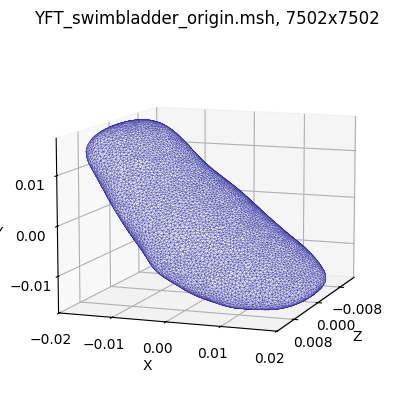

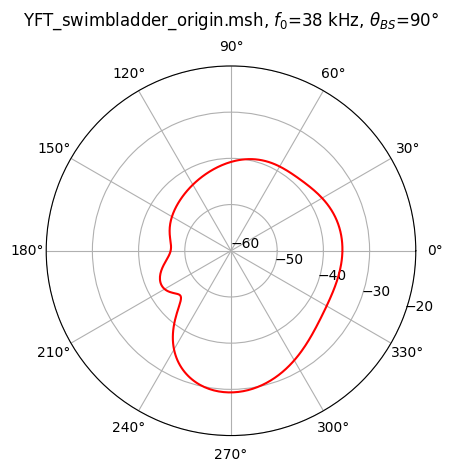

# YFT_swimbladder_origin.msh
# th0=270 ph0=0 f0=38000 c0=1480
0	0.0160605
1	0.0160719
2	0.0160784
3	0.0160797
4	0.0160755
5	0.0160656
6	0.0160496
7	0.0160273
8	0.0159985
9	0.0159631
10	0.0159208
11	0.0158716
12	0.0158153
13	0.0157521
14	0.0156817
15	0.0156044
16	0.0155202
17	0.0154291
18	0.0153316
19	0.0152276
20	0.0151176
21	0.0150019
22	0.0148807
23	0.0147546
24	0.0146241
25	0.0144896
26	0.0143517
27	0.014211
28	0.0140681
29	0.0139237
30	0.0137784
31	0.013633
32	0.0134882
33	0.0133447
34	0.0132032
35	0.0130644
36	0.012929
37	0.0127976
38	0.0126708
39	0.0125492
40	0.0124332
41	0.0123232
42	0.0122196
43	0.0121226
44	0.0120323
45	0.0119488
46	0.0118721
47	0.0118019
48	0.0117382
49	0.0116805
50	0.0116285
51	0.0115818
52	0.0115397
53	0.0115018
54	0.0114674
55	0.0114358
56	0.0114065
57	0.0113787
58	0.0113519
59	0.0113253
60	0.0112983
61	0.0112705
62	0.0112411
63	0.0112098
64	0.0111761
65	0.0111395
66	0.0110998
67	0.0110567
68	0.0110098
69	0.0109592
70	0.0109045
71	0.0108459
72	0.0107831
73

In [ ]:
# MM 1.11.2026: scattering from soft body using pytorch
# !pip install numpy torch matplotlib

# plane wave scattering from soft target in salt water
# input: msh ascii 2.2 file
# output: 1-deg scattering pattern

from numpy import pi, cos, sin, log10, array, linspace
#import sys
import torch
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

# input parameters
datapath = "../msh/"
fname = 'Yellowfin_Tuna_752x1500.msh' #if len(sys.argv)<=1 else sys.argv[1]
fname = 'sphere-1.905_4098x8092.msh'  #if len(sys.argv)<=1 else sys.argv[1]
fname = 'sphere-1.905-600.msh'
fname = 'simplify10_YFT_swimbladder_origin.msh'
fname = 'YFT_swimbladder_origin.msh'
th = 270   #if len(sys.argv)<=2 else float(sys.argv[2])
f0 = 38e3  #if len(sys.argv)<=3 else float(sys.argv[3])
c0 = 1480  #if len(sys.argv)<=4 else float(sys.argv[4])
ph = 0     #if len(sys.argv)<=5 else float(sys.argv[5])

k = 2 * pi * f0 / c0

#  GPU (MPS float32)
Ry = torch.tensor([
    [cos(ph*pi/180), 0, sin(ph*pi/180)],
    [0, 1, 0],
    [-sin(ph*pi/180), 0, cos(ph*pi/180)]
], dtype=torch.float32, device=device)
d = Ry @ torch.tensor([cos(th*pi/180+pi), sin(th*pi/180+pi), 0], dtype=torch.float32, device=device)

with open(datapath + fname) as f: lines = f.readlines()
n = int(lines[4])
v = [list(map(float, lines[5+i].split()[1:4])) for i in range(n)]
m = int(lines[n+7])
e = [list(map(lambda x: int(x)-1, lines[n+8+i].split()[5:8])) for i in range(m)]

# GPU
v = torch.tensor(v, dtype=torch.float32, device=device)
e = torch.tensor(e, dtype=torch.long, device=device)
#x = v[e].mean(dim=1)  # shape: (m, 3)
x, m = v, len(v)
diff = x.unsqueeze(1) - x.unsqueeze(0)  # Kształt: (m, m, 3)
r = torch.norm(diff, dim=2)             # Kształt: (m, m)
S = torch.empty((m, m), dtype=torch.complex64, device=device)
mask_zero = (r == 0)
mask_nonzero = ~mask_zero
r_nz = r[mask_nonzero].to(torch.complex64)
S[mask_nonzero] = torch.exp(1j * k * r_nz) / r_nz / (4 * pi)
S[mask_zero] = k / 4 + 1j * k / (4 * pi)
f_vec = torch.exp(1j * k * (x @ d))

phi_cpu = torch.linalg.solve(S.cpu(), -f_vec.cpu())
phi = phi_cpu.to(device) # phi back to GPU

# Far field: GPU
angles = torch.arange(360, dtype=torch.float32, device=device) * pi / 180 + pi
r1_vectors = torch.stack([torch.cos(angles), torch.sin(angles), torch.zeros_like(angles)], dim=1)
r1 = r1_vectors @ Ry.T  # (360, 3)
S_far = torch.exp(-1j * k * (r1 @ x.T)) / (4 * pi)
psc = S_far @ phi             # GPU: matrix-vector
psc = psc.cpu().abs().numpy() # to CPU

#print("\n".join(["%d\t%.6f" % (i, psc[i]) for i in range(len(psc))]))

# plot mesh
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
tri = [[array(v[i].cpu().numpy()) for i in t] for t in e]
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
mesh_collection = Poly3DCollection(tri, alpha=0.6)
mesh_collection.set_facecolor('white')
mesh_collection.set_edgecolor('darkblue')
mesh_collection.set_linewidth(0.2)
ax.add_collection3d(mesh_collection)
v_arr = array(v.cpu().numpy())
x_min, x_max = v_arr[:, 0].min(), v_arr[:, 0].max()
y_min, y_max = v_arr[:, 1].min(), v_arr[:, 1].max()
z_min, z_max = v_arr[:, 2].min(), v_arr[:, 2].max()
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_zlim(z_min, z_max)
x_range = x_max - x_min
y_range = y_max - y_min
z_range = z_max - z_min
ax.set_box_aspect((x_range, y_range, z_range))
ax.view_init(elev=10, azim=20, vertical_axis='y')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title(r"%s, %dx%d"%(fname,n,m))
from matplotlib.ticker import MaxNLocator
ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
ax.zaxis.set_major_locator(MaxNLocator(nbins=4))
plt.savefig("yft_torch_1.svg", format="svg", bbox_inches="tight")
plt.show()

# plot solution
import matplotlib.pyplot as plt
angles = linspace(0, 2 * pi, 360, endpoint=False)
values_db = 20 * log10([abs(p) for p in psc])
vmin, vmax = -60, -20
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(angles, values_db, color='red')
ax.set_ylim(vmin, vmax)
ax.set_rticks(linspace(vmin, vmax, 5))
ax.set_xticks(linspace(0, 2*pi-pi/6, 12))  # 30deg
ax.set_rlabel_position(-20)
ax.grid(True)
ax.set_title(r"%s, $f_0$=%g kHz, $\theta_{BS}$=%g$\degree$"%(fname,f0/1e3,(th+180)%360), va='bottom')
plt.savefig("yft_torch_2.svg", format="svg", bbox_inches="tight")
plt.show()

# print
s = "# %s\n# th0=%g ph0=0 f0=%g c0=%g\n"%(fname,th,f0,c0)
s += "\n".join(["%d\t%g"%(i,abs(psc[i])) for i in range(len(psc))])
print(s)
with open("yft_torch_3.txt", "w") as f: print(s,file=f)